# 02 — Barato, normal ou caro: scikit-learn → tabela → árvore
Projeto 02 — Grupo 09.

Fluxo pedido:
1. Usar Price com K-Means do scikit-learn para criar três grupos.
2. Ordenar os centroides e acrescentar a coluna ClassePreco à tabela.
3. Prever essa classe a partir das características da casa com uma árvore de raiz.

A árvore tem três classes, Gini e os hiperparâmetros max_depth, min_samples_split e
min_samples_leaf. scikit-learn é usado na criação das classes, não na árvore.

In [1]:
from pathlib import Path
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython import get_ipython
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from libs.data import load_housing, PRICE_LABELS, FEATURES, prepare_partitions, HousingPreparation

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("svg")
SEED = 42
houses = load_housing(download=True)
print(houses.attrs["source"])
print({"Python": platform.python_version(), "pandas": pd.__version__, "NumPy": np.__version__, "scikit-learn": sklearn.__version__})

{'dataset': 'dansbecker/melbourne-housing-snapshot', 'ficheiro': 'melb_data.csv', 'sha256': '3e449c3e95088da8a3a6b10331a5703f2c951d0740f317f97ed9baf0db1fd9f8', 'linhas_originais': 13580, 'duplicados_exatos_removidos': 0, 'preços_inválidos_removidos': 0, 'linhas_utilizadas': 13580}
{'Python': '3.11.6', 'pandas': '3.0.1', 'NumPy': '1.26.4', 'scikit-learn': '1.8.0'}


## Separar antes de criar as classes
A separação é aproximadamente 60/20/20 por morada. Não é estratificada por classes que
ainda não foram aprendidas. Vendas da mesma morada ficam juntas. Isto evita contaminação
entre conjuntos e mantém as fronteiras de preço independentes do teste.

In [2]:
from itertools import product
from libs.decisiontrees import DecisionTree
from libs.metrics import classification_metrics

parts, bands = prepare_partitions(houses, seed=SEED)
train, validation, test = parts
display(pd.DataFrame({"classe": PRICE_LABELS, "centro_preço_treino": bands.centers_}))
display(pd.DataFrame({
    name: part["ClassePreco"].value_counts().reindex(PRICE_LABELS, fill_value=0)
    for name, part in zip(["treino", "validação", "teste"], parts)
}))
print("Fronteiras de preço:", bands.boundaries_)

,classe,centro_preço_treino
0,barato,7.014559e+05
1,normal,1.465988e+06
2,caro,2.858575e+06


,treino,validação,teste
ClassePreco,,,
barato,5079,1687,1672
normal,2566,882,874
caro,504,147,169


Fronteiras de preço: [1083721.94045645 2162281.57638966]


## Acrescentar à tabela e exportar
ClassePreco é a coluna textual; PriceClass codifica barato=0, normal=1, caro=2.
O CSV completo classificado fica em data/melbourne/melb_classificado.csv e pode ser
recriado ao executar este notebook. A tabela resumida em reports permite verificar as classes
e a separação sem redistribuir todos os atributos da fonte.

In [3]:
classified = pd.concat([
    part.assign(Particao=name) for name, part in zip(["treino", "validacao", "teste"], parts)
]).sort_values("SourceRow")
output = Path("data/melbourne/melb_classificado.csv")
output.parent.mkdir(parents=True, exist_ok=True)
classified.to_csv(output, index=False)
reports = Path("reports")
reports.mkdir(exist_ok=True)
classified[["SourceRow", "Price", "PriceClass", "ClassePreco", "Particao"]].to_csv(
    reports / "housing_price_classes.csv", index=False
)
display(classified[["SourceRow", "Price", "ClassePreco", "Rooms", "Type", "Distance", "Particao"]].head(12))
print("Tabela classificada:", output)

,SourceRow,Price,ClassePreco,Rooms,Type,Distance,Particao
0,0,1480000.0,normal,2,h,2.5,validacao
1,1,1035000.0,barato,2,h,2.5,validacao
2,2,1465000.0,normal,3,h,2.5,teste
3,3,850000.0,barato,3,h,2.5,validacao
4,4,1600000.0,normal,4,h,2.5,treino
5,5,941000.0,barato,2,h,2.5,teste
6,6,1876000.0,normal,3,h,2.5,treino
7,7,1636000.0,normal,2,h,2.5,teste
8,8,300000.0,barato,1,u,2.5,treino
9,9,1097000.0,normal,2,h,2.5,validacao


Tabela classificada: data\melbourne\melb_classificado.csv


## Preparar entradas e ajustar hiperparâmetros
Price e as duas colunas de classe ficam fora da matriz de entrada. A preparação usa
medianas e categorias do treino, aplicadas sem reajuste à validação e ao teste.
Escolhemos a configuração pela F1 macro da validação, que dá o mesmo peso às três classes.
Em empate, a grelha favorece a primeira configuração, começando pelas árvores menos profundas.

In [4]:
preparation = HousingPreparation().fit(train)
X_train, X_validation = preparation.transform(train), preparation.transform(validation)
y_train, y_validation = train["PriceClass"].to_numpy(), validation["PriceClass"].to_numpy()
print("Entradas da árvore:", preparation.feature_names_)
results = []
best_model, best_config, best_score = None, None, -1.0
started = time.perf_counter()
for depth, split, leaf in product([3, 5, 7], [20, 100], [10, 30]):
    config = {"max_depth": depth, "min_samples_split": split, "min_samples_leaf": leaf}
    model = DecisionTree(**config).fit(X_train, y_train)
    training = classification_metrics(y_train, model.predict(X_train))
    evaluation = classification_metrics(y_validation, model.predict(X_validation))
    results.append({
        **config, "accuracy_treino": training["accuracy"], "f1_macro_treino": training["macro_f1"],
        "accuracy_validação": evaluation["accuracy"], "f1_macro_validação": evaluation["macro_f1"],
    })
    if evaluation["macro_f1"] > best_score:
        best_model, best_config, best_score = model, config, evaluation["macro_f1"]
validation_results = pd.DataFrame(results).sort_values("f1_macro_validação", ascending=False, kind="stable")
display(validation_results)
print("Configuração escolhida:", best_config)
print(f"Tempo de pesquisa: {time.perf_counter() - started:.2f} s")
validation_results.to_csv(reports / "housing_validation.csv", index=False)

Entradas da árvore: ['Rooms', 'Distance', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Type=h', 'Type=t', 'Type=u']


,max_depth,min_samples_split,min_samples_leaf,accuracy_treino,f1_macro_treino,accuracy_validação,f1_macro_validação
8,7,20,10,0.820837,0.671077,0.801915,0.641600
10,7,100,10,0.815683,0.666174,0.802283,0.640456
9,7,20,30,0.814578,0.665835,0.797128,0.637362
11,7,100,30,0.813351,0.664568,0.797128,0.636747
6,5,100,10,0.796049,0.531377,0.784610,0.521288
5,5,20,30,0.794576,0.530037,0.783137,0.519863
7,5,100,30,0.794576,0.530037,0.783137,0.519863
4,5,20,10,0.796908,0.531688,0.782401,0.519434
0,3,20,10,0.746963,0.503475,0.749264,0.504503
1,3,20,30,0.746963,0.503475,0.749264,0.504503


Configuração escolhida: {'max_depth': 7, 'min_samples_split': 20, 'min_samples_leaf': 10}
Tempo de pesquisa: 2.71 s


## Avaliação final, sem reajustar pelo teste
A baseline prevê sempre a classe mais frequente do treino.
A matriz tem classes reais nas linhas e previstas nas colunas.
Além da accuracy, observamos F1 macro e recall de cada classe, sobretudo das casas caras.

,accuracy,macro_precision,macro_recall,macro_f1
baseline,0.615838,0.205279,0.333333,0.254084
árvore,0.804052,0.777546,0.638738,0.654223


,precision,recall,f1,support,classe
0,0.923331,0.835526,0.877237,1672,barato
1,0.649306,0.855835,0.738401,874,normal
2,0.760000,0.224852,0.347032,169,caro


,barato,normal,caro
barato,1397,275,0
normal,114,748,12
caro,2,129,38


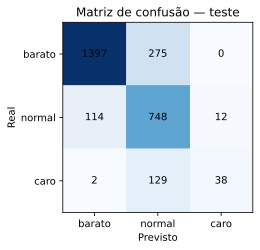

2825

In [5]:
X_test = preparation.transform(test)
y_test = test["PriceClass"].to_numpy()
predictions = best_model.predict(X_test)
baseline_class = int(np.bincount(y_train, minlength=3).argmax())
baseline_report = classification_metrics(y_test, np.full(len(y_test), baseline_class))
tree_report = classification_metrics(y_test, predictions)
scalars = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
display(pd.DataFrame({
    "baseline": {k: baseline_report[k] for k in scalars},
    "árvore": {k: tree_report[k] for k in scalars},
}).T)
per_class = pd.DataFrame(tree_report["per_class"])
per_class["classe"] = PRICE_LABELS
display(per_class.drop(columns="class"))
confusion = pd.DataFrame(tree_report["confusion_matrix"], index=PRICE_LABELS, columns=PRICE_LABELS)
display(confusion)
fig, ax = plt.subplots(figsize=(4.8, 3.6))
ax.imshow(confusion, cmap="Blues")
ax.set(xticks=range(3), yticks=range(3), xticklabels=PRICE_LABELS, yticklabels=PRICE_LABELS,
       xlabel="Previsto", ylabel="Real", title="Matriz de confusão — teste")
for row in range(3):
    for col in range(3):
        ax.text(col, row, int(confusion.iloc[row, col]), ha="center", va="center")
plt.tight_layout()
plt.show()
record = {
    "source": houses.attrs["source"], "seed": SEED, "features": preparation.feature_names_,
    "split_rows": dict(zip(["train", "validation", "test"], map(len, parts))),
    "price_centers": bands.centers_, "price_boundaries": bands.boundaries_,
    "price_classes": PRICE_LABELS, "best_config": best_config,
    "validation_macro_f1": best_score, "baseline": baseline_report, "tree": tree_report,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
def json_value(value):
    return value.tolist() if isinstance(value, np.ndarray) else value.item()
(reports / "housing_results.json").write_text(
    json.dumps(record, ensure_ascii=False, indent=2, default=json_value), encoding="utf-8"
)

## Alcance dos resultados
A árvore tenta reproduzir classes derivadas do preço, não uma avaliação independente de
«bom negócio». O K-Means em preços originais é sensível à cauda de imóveis de luxo.
Não existe garantia de grupos equilibrados.

A avaliação refere-se a moradas não usadas no treino dentro desta base histórica.
Não demonstra generalização temporal, a outras cidades ou a Portugal.

## Interpretação desta primeira experiência
A configuração escolhida na validação foi max_depth=7, min_samples_split=20 e min_samples_leaf=10. A F1 macro foi 0,6711 no treino, 0,6416 na validação e 0,6542 no teste; a proximidade entre validação e teste não demonstra generalização a outras populações.

No teste, a árvore acertou 80,41%, acima dos 61,58% da baseline, e obteve F1 macro de 0,6542. Contudo, só identificou 38 das 169 casas caras (22,49%); 129 foram classificadas como normais. A média global esconde, portanto, uma dificuldade importante na classe minoritária.

Estes resultados não justificam chamar ao modelo uma avaliação de preço justo: a árvore reproduz grupos aprendidos a partir do preço de venda. A análise dos erros deve fundamentar experiências futuras sem voltar a usar este teste para escolher configurações.